In [ ]:
!pip install FRECKLL

In [ ]:
# !git clone https://github.com/MartianColonist/POSEIDON.git
# %cd POSEIDON
# !pip install -e .

fatal: destination path 'POSEIDON' already exists and is not an empty directory.
/content/POSEIDON
Obtaining file:///content/POSEIDON
  Preparing metadata (setup.py) ... done
  Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.0 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Attempting uninstall: POSEIDON
    Found existing installation: POSEIDON 1.4.0
    Uninstalling POSEIDON-1.4.0:
      Successfully uninstalled POSEIDON-1.4.0
  Running setup.py develop for POSEIDON
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
acepython 0.0.21 requires numpy>=2.0.2, but you have numpy 1.26.4 which is incompatible.
freckll 0.0.1 

In [ ]:
!pip install acepython -q

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u

from freckll.io.loader import default_network_loader
from freckll.ace import equil_chemistry_ace
from freckll.solver import Rosenbrock
from freckll.plot import plot_vmr

In [ ]:
n_layers    = 100
T_iso       = 1500                              # single temperature, Kelvin
temperature = np.full(n_layers, T_iso) << u.K  # same T at every layer
pressure    = np.logspace(2, -5, n_layers) << u.bar
kzz         = np.full(n_layers, 1e8) << u.cm**2/u.s

In [ ]:
network   = default_network_loader("venot-methanol-2020-reduced")

equil_vmr = equil_chemistry_ace(
    temperature=temperature,
    pressure=pressure,
    composition=network.species,
    elements=["H", "He", "C", "N", "O"],
    abundances=[12, 10.93, 8.39, 7.86, 8.73],  # solar abundances
)

print("Equilibrium VMR shape:", equil_vmr.shape)
print("Number of species:", len(network.species))

Equilibrium VMR shape: (44, 100)
Number of species: 44


In [ ]:
solver = Rosenbrock(network=network)

solver.set_system_parameters(
    temperature=temperature,
    pressure=pressure,
    kzz=kzz,
    planet_radius=1.37 * u.Rjup,
    planet_mass=0.87 * u.Mjup,
)

result = solver.solve(
    vmr=equil_vmr,
    t_span=[0, 1e16],
    enable_diffusion=True,   # enable Kzz mixing!
    maxiter=1000,
)

print("Success:", result["success"])

Success: True


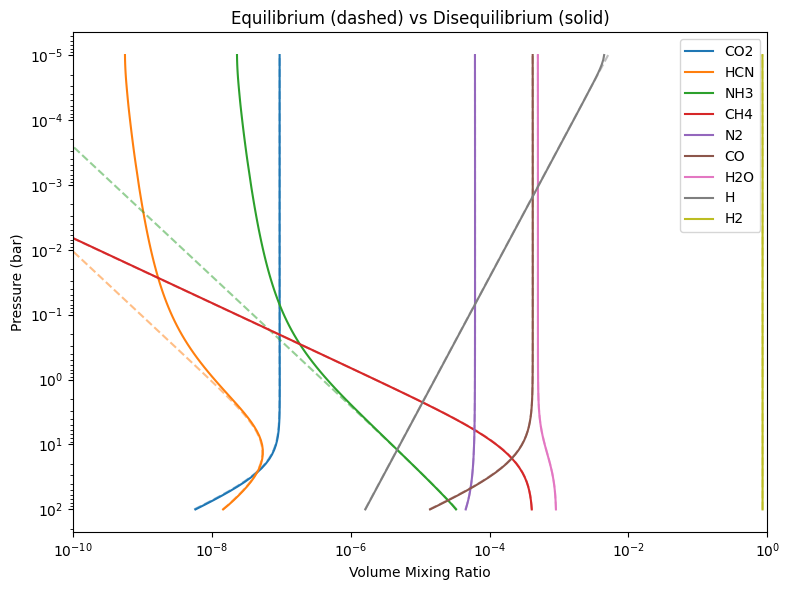

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_vmr(
    result["vmr"][-1],
    result["pressure"],
    result["species"],
    initial_vmr=result["initial_vmr"],
    xlims=(1e-10, 1e0),
    ax=ax
)
ax.set_title("Equilibrium (dashed) vs Disequilibrium (solid)")
plt.tight_layout()
plt.show()

In [ ]:
species_names = [str(s) for s in result["species"]]
final_vmr     = result["vmr"][-1]   # shape: (n_species, n_layers)

molecules = ["H2O", "CH4", "CO", "CO2", "NH3"]
for mol in molecules:
    if mol in species_names:
        idx = species_names.index(mol)
        print(f"{mol}: mean VMR = {final_vmr[idx].mean():.3e}")
    else:
        print(f"{mol}: NOT FOUND in network species list")

H2O: mean VMR = 5.472e-04
CH4: mean VMR = 4.931e-05
CO: mean VMR = 3.698e-04
CO2: mean VMR = 8.675e-08
NH3: mean VMR = 2.432e-06


In [ ]:

species_names = [str(s) for s in result["species"]]
final_vmr = result["vmr"][-1]  # shape: (n_species, n_layers)

def get_vmr_profile(mol):
    idx = species_names.index(mol)
    return np.array(final_vmr[idx])  # shape: (n_layers,)

h2o_profile  = get_vmr_profile("H2O")
ch4_profile  = get_vmr_profile("CH4")
co_profile   = get_vmr_profile("CO")
co2_profile  = get_vmr_profile("CO2")
nh3_profile  = get_vmr_profile("NH3")
np.save("h2o_profile.npy", h2o_profile)
np.save("ch4_profile.npy", ch4_profile)
np.save("co_profile.npy", co_profile)
np.save("co2_profile.npy", co2_profile)
np.save("nh3_profile.npy", nh3_profile)

# FRECKLL pressure grid (in bar, stripped of units)
freckll_pressure = np.array(result["pressure"].to(u.bar).value)

print("Pressure grid shape:", freckll_pressure.shape)
print("VMR profile shape:", h2o_profile.shape)
print("Pressure range: {:.2e} to {:.2e} bar".format(
    freckll_pressure.min(), freckll_pressure.max()))

Pressure grid shape: (100,)
VMR profile shape: (100,)
Pressure range: 1.00e-05 to 1.00e+02 bar
